# 验证 notebook：可皮的云台为什么抬不起头、为什么失控了

配套视频《手推到狗跑》PID：积分消偏差，微分给阻尼。

**用法**：先在纸上完成练习单的推导，再运行这里的代码，把你推出来的公式和仿真结果对照。
每一节最后有一个“填你的公式”的格子，算出来和仿真一致才算推对。

**对象**：RM 云台俯仰轴（一个转动轴 + 枪管重力矩），外加恒定重力矩 τ_L。参数是教学用的数，不是某台真实云台的参数；重力矩 m g d cos q 在俯仰角变化不大时近似为常数。

$$J\dot v + b v = K_t u - \tau_L,\qquad \dot q = v,\qquad u\in[-1,1]$$

| 符号 | 含义 | 数值 | 单位 |
|---|---|---|---|
| J | 转动惯量 | 0.01 | kg·m² |
| b | 粘性阻尼 | 0.02 | N·m·s/rad |
| K_t | 命令到力矩的系数 | 0.5 | N·m / 单位命令 |
| τ_L | 枪管重力矩（1.5 s 时装上枪管） | 0.05 | N·m |
| r | 目标角（0.1 s 时阶跃） | 0.2 | rad |
| T_s | 控制周期 | 1 | ms |

仿真细节见同目录 `pid_sim.py`：控制器 1 ms 零阶保持，对象 0.1 ms 子步 RK4；D 对测量微分；I 用条件积分。
所有结果都是课程仿真，不是实机数据。

In [1]:
import numpy as np, matplotlib.pyplot as plt, json
from pid_sim import *
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
TL = 0.05
results = {}

def plot(cases, title, t_max=4.0):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for label, c in cases:
        r = simulate(c)
        ax.plot(r['t'], r['q'], label=label)
    ax.plot(r['t'], r['r'], 'k--', lw=1, label='目标')
    ax.axvline(1.5, color='gray', lw=0.8, ls=':')
    ax.text(1.52, 0.02, '装枪管', color='gray')
    ax.set_xlim(0, t_max); ax.set_xlabel('时间 t / s'); ax.set_ylabel('俯仰角 q / rad')
    ax.set_title(title); ax.legend(loc='lower right'); plt.show()

In [2]:
# 0. 模型自检：不加负载时，检查无负载时的超调（P 73.508%，PD 16.344%）
for kd in [0, 0.16]:
    c = Case('chk', kp=2, kd=kd, t_load=99)
    os_ = overshoot_pct(simulate(c), c, t_until=4)
    print(f'Kd={kd}: 超调 {os_:.3f}%')
    results[f'check_kd{kd}'] = round(os_, 3)

Kd=0: 超调 73.508%
Kd=0.16: 超调 16.344%


## 1. 只用 P：云台抬不起头

**手推（练习单第 1 题）**：稳态时 $\dot v=0,\ v=0$，代入对象和 $u=K_p(r-q)$，求稳态误差 $e_\infty=r-q_\infty$。

P: Kp=2  仿真稳态误差 = 49.93 mrad,  加负载前超调 = 73.51%
P 拉满: Kp=8  仿真稳态误差 = 12.49 mrad,  加负载前超调 = 82.33%


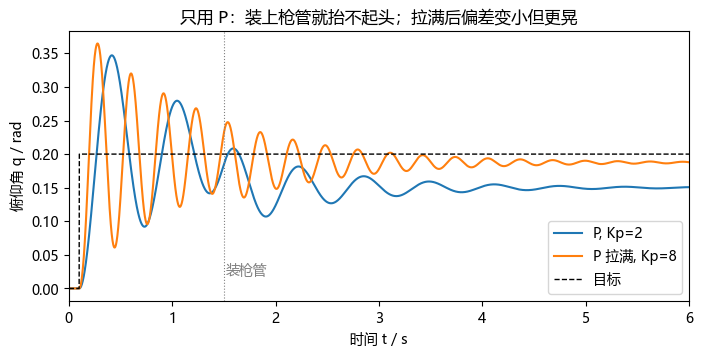

In [3]:
c_p2 = Case('P', kp=2, tau_load=TL, t_end=8)
c_p8 = Case('P 拉满', kp=8, tau_load=TL, t_end=8)
for c in [c_p2, c_p8]:
    r = simulate(c)
    print(f'{c.name}: Kp={c.kp}  仿真稳态误差 = {steady_error(r, c)*1000:.2f} mrad,  加负载前超调 = {overshoot_pct(r, c):.2f}%')
    results[f'P_kp{c.kp}'] = {'e_ss_mrad': round(steady_error(r, c)*1000, 2), 'overshoot_pct': round(overshoot_pct(r, c), 2)}
plot([('P, Kp=2', c_p2), ('P 拉满, Kp=8', c_p8)], '只用 P：装上枪管就抬不起头；拉满后偏差变小但更晃', t_max=6)

In [4]:
# 填你的公式：e_inf = ?（用 TL, KT, kp 表示）
def my_e_inf(kp):
    return TL / (KT * kp)   # ← 把这一行换成你自己推的结果
for kp in [2, 8]:
    print(f'Kp={kp}: 你的公式 {my_e_inf(kp)*1000:.2f} mrad')

Kp=2: 你的公式 50.00 mrad
Kp=8: 你的公式 12.50 mrad


**拉满的代价**：没有 D 时阻尼比 $\zeta=\dfrac{b}{2\sqrt{J K_t K_p}}$，$K_p$ 变成 4 倍，$\zeta$ 只剩一半。

In [5]:
for kp in [2, 8]:
    print(f'Kp={kp}: zeta = {zeta_pd(kp, 0):.3f},  wn = {omega_n(kp):.1f} rad/s')

Kp=2: zeta = 0.100,  wn = 10.0 rad/s
Kp=8: zeta = 0.050,  wn = 20.0 rad/s


## 2. 加 I：偏差被“记住”并补回来

**手推（练习单第 2 题）**：积分状态 $I$ 满足 $\dot I = K_i e$。如果系统最终停住不动，$I$ 也必须停止变化，于是 $e=?$ 此时 $I$ 停在多少？

PID 稳态误差 = 0.000 mrad
积分项最终值 I = 0.1000  （你的推导：I_inf = TL/KT = 0.1000）


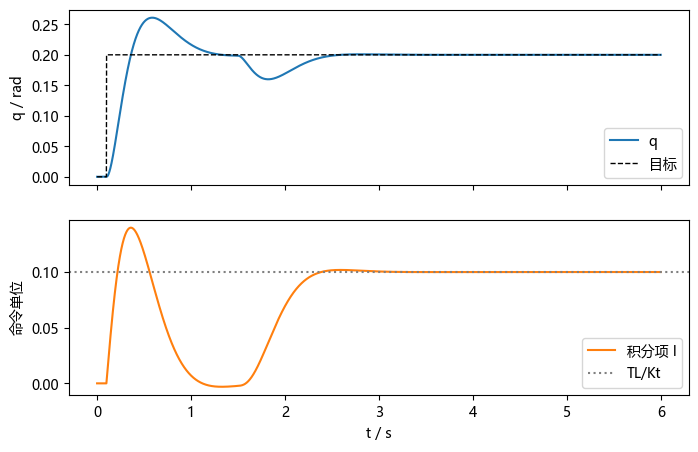

In [6]:
c_pid = Case('PID', kp=2, ki=5, kd=0.3, tau_load=TL, t_end=6)
r = simulate(c_pid)
print(f'PID 稳态误差 = {steady_error(r, c_pid)*1000:.3f} mrad')
print(f'积分项最终值 I = {r["I"][-1]:.4f}  （你的推导：I_inf = TL/KT = {TL/KT:.4f}）')
results['PID'] = {'kp': 2, 'ki': 5, 'kd': 0.3, 'e_ss_mrad': round(steady_error(r, c_pid)*1000, 3),
                  'I_final': round(float(r['I'][-1]), 4), 'overshoot_pct': round(overshoot_pct(r, c_pid), 2)}
fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(r['t'], r['q'], label='q'); ax[0].plot(r['t'], r['r'], 'k--', lw=1, label='目标'); ax[0].legend(); ax[0].set_ylabel('q / rad')
ax[1].plot(r['t'], r['I'], color='tab:orange', label='积分项 I'); ax[1].axhline(TL/KT, color='gray', ls=':', label='TL/Kt'); ax[1].legend(); ax[1].set_ylabel('命令单位'); ax[1].set_xlabel('t / s')
plt.show()

## 3. 加 D：给系统装上减震器

**手推（练习单第 3 题）**：令 $\tau_L=0$，代入 $u=K_p(r-q)-K_d\dot q$，写出闭环方程，并整理成 $\ddot q + 2\zeta\omega_n\dot q + \omega_n^2 q = \omega_n^2 r$ 的形式，求 $\omega_n$ 和 $\zeta$。

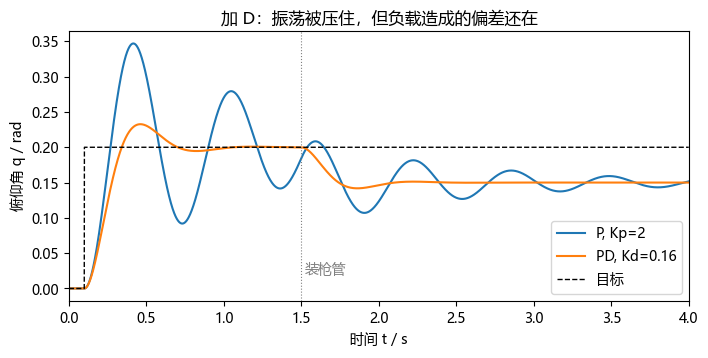

Kd=0: zeta=0.10  公式超调=72.92%  仿真超调=73.51%
Kd=0.16: zeta=0.50  公式超调=16.30%  仿真超调=16.34%


In [7]:
c_pd = Case('PD', kp=2, kd=0.16, tau_load=TL)
plot([('P, Kp=2', Case('P', kp=2, tau_load=TL)), ('PD, Kd=0.16', c_pd)], '加 D：振荡被压住，但负载造成的偏差还在')
for kd in [0, 0.16]:
    c = Case('x', kp=2, kd=kd, t_load=99)
    sim_os = overshoot_pct(simulate(c), c, t_until=4)
    z = zeta_pd(2, kd)
    print(f'Kd={kd}: zeta={z:.2f}  公式超调={overshoot_formula(z):.2f}%  仿真超调={sim_os:.2f}%')
    results[f'PD_kd{kd}'] = {'zeta': round(z, 3), 'os_formula': round(overshoot_formula(z), 2), 'os_sim': round(sim_os, 2)}

In [8]:
# 填你的公式：zeta(kp, kd) = ?
def my_zeta(kp, kd):
    return (B + KT * kd) / (2 * np.sqrt(J * KT * kp))   # ← 换成你自己推的结果
print(my_zeta(2, 0), my_zeta(2, 0.16))

0.09999999999999999 0.5


## 4. 为什么可皮加了 I 反而失控了

**手推（练习单第 4 题）**：令 $\tau_L=0$，在 PID 下对闭环方程再求一次导，消去积分，写出三阶特征多项式
$$J s^3 + (b+K_tK_d)s^2 + K_tK_p s + K_tK_i = 0$$
三阶多项式的稳定条件（所有根实部为负）是：各系数为正，且 $(b+K_tK_d)\,K_tK_p > J\,K_tK_i$。这个条件这里先直接用，证明留到后面讲稳定性判据的时候。
请算出：没有 D 时 $K_i$ 最大能取多少？$K_d=0.3$ 时呢？

没有 D：Ki < 4.0    Kd=0.3：Ki < 34.0


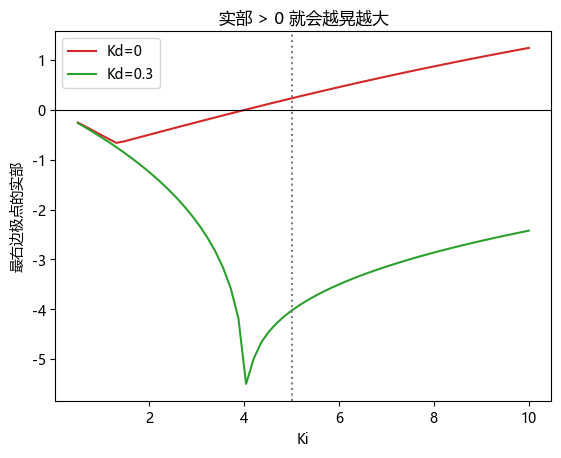

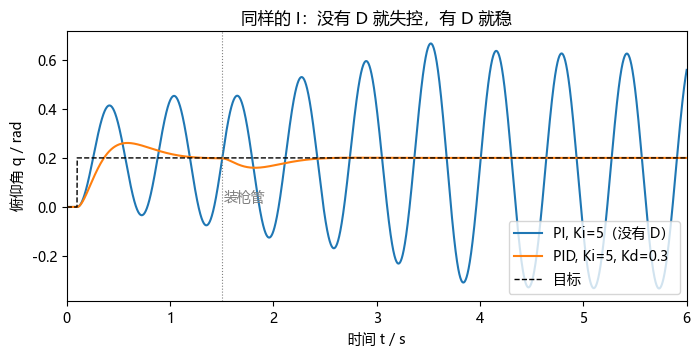

In [9]:
def ki_limit(kp, kd):
    return (B + KT * kd) * kp / J
print(f'没有 D：Ki < {ki_limit(2, 0):.1f}    Kd=0.3：Ki < {ki_limit(2, 0.3):.1f}')
results['ki_limit'] = {'no_D': ki_limit(2, 0), 'kd0.3': ki_limit(2, 0.3)}
kis = np.linspace(0.5, 10, 60)
for kd, style in [(0, 'tab:red'), (0.3, 'tab:green')]:
    mx = [max(np.roots([J, B + KT*kd, KT*2, KT*ki]).real) for ki in kis]
    plt.plot(kis, mx, color=style, label=f'Kd={kd}')
plt.axhline(0, color='k', lw=0.8); plt.axvline(5, color='gray', ls=':')
plt.xlabel('Ki'); plt.ylabel('最右边极点的实部'); plt.title('实部 > 0 就会越晃越大'); plt.legend(); plt.show()
plot([('PI, Ki=5（没有 D）', Case('PI', kp=2, ki=5, tau_load=TL, t_end=6)), ('PID, Ki=5, Kd=0.3', c_pid)], '同样的 I：没有 D 就失控，有 D 就稳', t_max=6)

## 5. D 的代价：放大测量噪声

**手推（练习单第 5 题）**：位置测量带独立噪声，标准差 $\sigma$。用差分 $(y_k-y_{k-1})/T_s$ 估速度，速度噪声的标准差是多少？

In [10]:
sigma = 0.005
print(f'理论：sqrt(2)*sigma/Ts = {np.sqrt(2)*sigma/TS:.3f} rad/s')
rng = np.random.default_rng(20261015)
n = rng.normal(0, sigma, 200000)
print(f'抽样：{np.std(np.diff(n)/TS):.3f} rad/s')
rows = {}
for tf in [0, 0.02]:
    c = Case('噪声', kp=2, ki=5, kd=0.3, tau_f=tf, noise_sigma=sigma, tau_load=TL, t_end=6)
    r = simulate(c); m = r['t'] > 2.5
    rows[tf] = {'u_std': round(float(np.std(r['u'][m])), 3), 'sat_pct': round(float(np.mean(np.abs(r['u']) >= 0.999)*100), 1),
                'q_std_mrad': round(float(np.std(r['q'][r['t'] > 3]))*1000, 2)}
    print(f'tau_f={tf*1000:.0f} ms: 命令标准差 {rows[tf]["u_std"]},  饱和比例 {rows[tf]["sat_pct"]}%,  俯仰角抖动 {rows[tf]["q_std_mrad"]} mrad')
results['noise'] = {'sigma': sigma, 'rate_sigma_theory': round(np.sqrt(2)*sigma/TS, 3), 'unfiltered': rows[0], 'filtered_20ms': rows[0.02]}

理论：sqrt(2)*sigma/Ts = 7.071 rad/s


抽样：7.089 rad/s


tau_f=0 ms: 命令标准差 0.868,  饱和比例 64.4%,  俯仰角抖动 26.12 mrad
tau_f=20 ms: 命令标准差 0.083,  饱和比例 0.0%,  俯仰角抖动 0.57 mrad


In [11]:
import pathlib
pathlib.Path('results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(results, ensure_ascii=False, indent=2))

{
  "check_kd0": 73.508,
  "check_kd0.16": 16.344,
  "P_kp2": {
    "e_ss_mrad": 49.93,
    "overshoot_pct": 73.51
  },
  "P_kp8": {
    "e_ss_mrad": 12.49,
    "overshoot_pct": 82.33
  },
  "PID": {
    "kp": 2,
    "ki": 5,
    "kd": 0.3,
    "e_ss_mrad": 0.0,
    "I_final": 0.1,
    "overshoot_pct": 30.46
  },
  "PD_kd0": {
    "zeta": 0.1,
    "os_formula": 72.92,
    "os_sim": 73.51
  },
  "PD_kd0.16": {
    "zeta": 0.5,
    "os_formula": 16.3,
    "os_sim": 16.34
  },
  "ki_limit": {
    "no_D": 4.0,
    "kd0.3": 33.99999999999999
  },
  "noise": {
    "sigma": 0.005,
    "rate_sigma_theory": 7.071,
    "unfiltered": {
      "u_std": 0.868,
      "sat_pct": 64.4,
      "q_std_mrad": 26.12
    },
    "filtered_20ms": {
      "u_std": 0.083,
      "sat_pct": 0.0,
      "q_std_mrad": 0.57
    }
  }
}


## 作业（发到评论区）

1. 把重力矩 τ_L 改成 0.1 N·m，只用 P（Kp=2），先手算稳态误差，再用仿真验证。
2. 没有 D 时，把 Ki 设成 3.9 和 4.1 各跑一次，描述两条曲线的区别。
3. 可皮说：“Kp 拉到 20，偏差就只有 5 mrad 了！”用第 1 节和第 3 节的公式解释，为什么这不是好主意。